# 06 · Risultati, sensibilità e prestazioni

**Domanda di ricerca.** Una strategia di market making a breve termine, attiva solo nei periodi di bassa volatilità, resta profittevole quando le regole di esecuzione L2 vengono sostituite da una simulazione della coda reale basata su dati L3 e L4?

**Criterio di risposta (piano, §5.2).** La strategia è considerata sostenibile solo se il P&L netto resta positivo nel test, l'inventario è sotto controllo e il risultato non dipende da una singola giornata. Un guadagno che compare solo con `touch` non basta.

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")                      # sessioni di test, strategia selezionata
validation = R.load(ROOT, "validation")          # griglia di parametri sulle sessioni di validazione
ablation = R.load(ROOT, "ablation")              # test ripetuto senza filtro di volatilità
variants = R.load(ROOT, "variants")              # varianti: inventory skew e imbalance
selected = R.load_json(ROOT, "selected_params")  # parametri scelti in validazione

from market_making_tesi.evaluation import bootstrap_mean_ci
NET = {"fi2010": "final_equity", "itch": "net_nasdaq_base", "hyperliquid": "net_tier0"}
rows = []
for name, column in NET.items():
    for model, g in test[test.dataset == name].groupby("model"):
        mean, low, high = bootstrap_mean_ci(g[column])
        rows.append({"dataset": R.DATASET_LABELS[name], "regola": R.LABELS[model], "_o": R.MODEL_ORDER.index(model),
                     "mean": mean, "low": low, "high": high, "positive": (g[column] > 0).mean(), "sessions": len(g)})
DS_ORDER = {R.DATASET_LABELS[n]: i for i, n in enumerate(NET)}
overview = (pd.DataFrame(rows).assign(_d=lambda f: f.dataset.map(DS_ORDER)).sort_values(["_d", "_o"])
            .set_index(["dataset", "regola"]).drop(columns=["_o", "_d"]))
overview.to_csv(ROOT / "results" / "tabella_riepilogo.csv")
it_q, it_t = overview.loc[("Nasdaq ITCH", "coda FIFO")], overview.loc[("Nasdaq ITCH", "touch")]
hl_q = overview.loc[("Hyperliquid BTC", "coda FIFO")]
R.show_box("Risposta in breve", [
    f"**No.** Con la coda reale la strategia perde: {it(it_q['mean'])} USD netti per sessione su Nasdaq ITCH "
    f"(positiva {R.nel(it_q['positive'], 0)} delle sessioni) e {it(hl_q['mean'], 1)} USD per ora su Hyperliquid.",
    f"Con la regola `touch` la stessa strategia, sugli stessi dati ITCH, guadagnerebbe {it(it_t['mean'])} USD per sessione.",
    "La profittabilità stimata dipende quindi dal modello di esecuzione più che dalla strategia.",
])

> **Risposta in breve**
>
> - **No.** Con la coda reale la strategia perde: -541 USD netti per sessione su Nasdaq ITCH (positiva nel 0% delle sessioni) e -47,3 USD per ora su Hyperliquid.
> - Con la regola `touch` la stessa strategia, sugli stessi dati ITCH, guadagnerebbe 139.086 USD per sessione.
> - La profittabilità stimata dipende quindi dal modello di esecuzione più che dalla strategia.

## 1. Riepilogo per dataset e regola

P&L netto medio per sessione con intervallo di confidenza al 95% (FI-2010: unità normalizzate, senza costi; ITCH: USD per sessione; Hyperliquid: USD per ora).

In [2]:
display(pd.DataFrame({
    "P&L netto medio (IC 95%)": [R.ci_text(r["mean"], r["low"], r["high"], 4 if ds == "FI-2010" else 1)
                                 for (ds, _), r in overview.iterrows()],
    "sessioni positive": overview.positive.map(lambda v: pct(v, 0)),
    "sessioni": overview.sessions,
}, index=overview.index))
hl_t = overview.loc[("Hyperliquid BTC", "touch")]
display(Markdown(
    f"**Nota su `touch` e Hyperliquid.** Al netto delle commissioni `touch` perde {it(-hl_t['mean'])} USD per ora: "
    "conta così tante esecuzioni (migliaia di volte quelle reali) che le commissioni superano lo spread incassato. "
    "Al lordo, come nel notebook 05, sembrerebbe invece molto profittevole."))

P&L netto medio (IC 95%)  \
dataset         regola                                             
FI-2010         touch                    0,3715 (0,2435; 0,5294)   
                price-through         -0,0044 (-0,0073; -0,0018)   
                cross                 -0,0141 (-0,0184; -0,0102)   
Nasdaq ITCH     touch           139.086,4 (121.853,7; 158.196,6)   
                price-through              -392,8 (-672,3; 81,3)   
                cross                -1.305,1 (-1.814,2; -876,7)   
                coda FIFO                -540,6 (-659,6; -434,8)   
Hyperliquid BTC touch          -93.878,4 (-120.920,8; -66.836,1)   
                price-through            -222,9 (-246,8; -199,0)   
                cross                    -192,8 (-229,3; -160,6)   
                coda FIFO                   -47,3 (-56,7; -34,2)   

                              sessioni positive  sessioni  
dataset         regola                                     
FI-2010         touch                      100%        35  
                price-through               20%        35  
                cross                        0%        35  
Nasdaq ITCH     touch                      100%        15  
                price-through                7%        15  
                cross                        0%        15  
                coda FIFO                    0%        15  
Hyperliquid BTC touch                        0%         4  
                price-through                0%         4  
                cross                        0%         4  
                coda FIFO                    0%         4

**Nota su `touch` e Hyperliquid.** Al netto delle commissioni `touch` perde 93.878 USD per ora: conta così tante esecuzioni (migliaia di volte quelle reali) che le commissioni superano lo spread incassato. Al lordo, come nel notebook 05, sembrerebbe invece molto profittevole.

## 2. Quanto sbagliano le regole L2

Per ITCH e Hyperliquid si conosce il risultato con la coda reale: si può quindi misurare di quante volte ogni regola L2 sovrastima le esecuzioni e di quanto sposta il P&L.

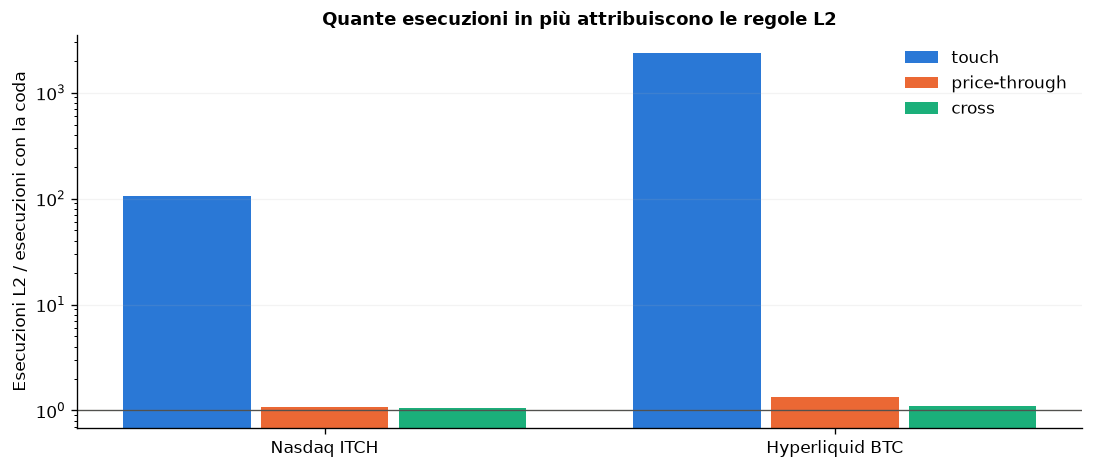

**Come leggerlo.** `touch` sovrastima le esecuzioni di due o tre ordini di grandezza (da circa 100 a oltre 1.000 volte). `price-through` e `cross` sono vicine nel numero di esecuzioni ma sbagliano comunque il P&L, perché non sanno quali esecuzioni sarebbero toccate alla quota.

In [3]:
bias_rows = []
for name in ["itch", "hyperliquid"]:
    ratios = R.fill_bias(test, name)
    pnl = test[test.dataset == name].pivot_table(index=["session", "symbol"], columns="model", values="final_equity")
    for model in ["touch", "price-through", "cross"]:
        bias_rows.append({"dataset": R.DATASET_LABELS[name], "regola": R.LABELS[model],
                          "esecuzioni rispetto alla coda": ratios[model].median(),
                          "errore medio sul P&L lordo": (pnl[model] - pnl["queue"]).mean()})
bias = pd.DataFrame(bias_rows)
display(bias.set_index(["dataset", "regola"]).style.format({"esecuzioni rispetto alla coda": "{:,.1f}×",
                                                             "errore medio sul P&L lordo": "{:+,.1f}"}))
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
names = bias.dataset.unique()
x = np.arange(len(names))
for i, model in enumerate(["touch", "price-through", "cross"]):
    vals = bias[bias.regola == R.LABELS[model]].set_index("dataset").loc[names, "esecuzioni rispetto alla coda"]
    ax.bar(x + (i - 1) * 0.27, vals, 0.25, color=R.COLORS[model], label=R.LABELS[model])
ax.axhline(1, color=R.INK, linewidth=0.8)
ax.set_xticks(x, names)
ax.set(yscale="log", ylabel="Esecuzioni L2 / esecuzioni con la coda", title="Quante esecuzioni in più attribuiscono le regole L2")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "bias_esecuzione.png", dpi=180, bbox_inches="tight")
plt.show()
display(Markdown("**Come leggerlo.** `touch` sovrastima le esecuzioni di due o tre ordini di grandezza (da circa 100 a oltre 1.000 volte). `price-through` e "
                 "`cross` sono vicine nel numero di esecuzioni ma sbagliano comunque il P&L, perché non sanno quali "
                 "esecuzioni sarebbero toccate alla quota."))

## 3. Perché la strategia perde con la coda reale

Scomposizione media per sessione con la coda FIFO.

In [4]:
parts = []
for name, fee in [("itch", "fees_nasdaq_base"), ("hyperliquid", "fees_tier0")]:
    table = R.decomposition_table(R.decomposition(test, name, fee), 2).loc[["coda FIFO"]]
    table.index = [R.DATASET_LABELS[name]]
    parts.append(table)
display(pd.concat(parts))
display(Markdown("**Come leggerlo.** Su ITCH pesano soprattutto la selezione avversa (il prezzo si muove contro dopo "
                 "l'esecuzione) e il costo per chiudere le coppie rimaste a metà; su Hyperliquid le commissioni."))

,spread incassato (edge maker),costo di liquidazione,movimento del prezzo sull'inventario,= P&L lordo,commissioni e rebate,= P&L netto
Nasdaq ITCH,"437,02","-268,61","-738,69","-570,29","29,70","-540,59"
Hyperliquid BTC,"0,59","-1,27","-2,57","-3,25","-44,04","-47,28"


**Come leggerlo.** Su ITCH pesano soprattutto la selezione avversa (il prezzo si muove contro dopo l'esecuzione) e il costo per chiudere le coppie rimaste a metà; su Hyperliquid le commissioni.

## 4. Il filtro di volatilità (ablazione)

Confronto sessione per sessione tra la strategia con filtro e la stessa strategia sempre attiva, con il modello di riferimento di ogni dataset (FI-2010: `price-through`; ITCH e Hyperliquid: coda FIFO).

In [5]:
filters = []
for name, ref in [("fi2010", "price-through"), ("itch", "queue"), ("hyperliquid", "queue")]:
    eff = R.filter_effect(test, ablation, name, NET[name])
    row = R.filter_table(eff, 4 if name == "fi2010" else 1).loc[[R.LABELS[ref]]]
    row.index = [R.DATASET_LABELS[name]]
    filters.append(row)
    eff.loc[[R.LABELS[ref]]].assign(dataset=R.DATASET_LABELS[name]).to_csv(
        ROOT / "results" / "tabella_filtro_volatilita.csv", mode="a" if len(filters) > 1 else "w",
        header=len(filters) == 1)
display(pd.concat(filters))
verdicts = []
for name, ref in [("fi2010", "price-through"), ("itch", "queue"), ("hyperliquid", "queue")]:
    r = R.filter_effect(test, ablation, name, NET[name]).loc[R.LABELS[ref]]
    word = "migliora" if r["IC95 basso"] > 0 else "peggiora" if r["IC95 alto"] < 0 else "non cambia in modo significativo"
    verdicts.append(f"su {R.DATASET_LABELS[name]} {word} il risultato")
display(Markdown(f"**Come leggerlo.** Il filtro {', '.join(verdicts)}. In nessun caso basta a rendere la strategia profittevole."))

,con filtro,sempre attiva,differenza (IC 95%),sessioni migliori con filtro,tempo in cui opera
FI-2010,"-0,0044","-0,0026","-0,0019 (-0,0033; -0,0004)",23%,85%
Nasdaq ITCH,"-540,6","-691,8","151,2 (59,7; 259,5)",80%,71%
Hyperliquid BTC,"-47,3","-122,3","75,1 (22,3; 127,8)",100%,32%


**Come leggerlo.** Il filtro su FI-2010 peggiora il risultato, su Nasdaq ITCH migliora il risultato, su Hyperliquid BTC migliora il risultato. In nessun caso basta a rendere la strategia profittevole.

## 5. Varianti: inventory skew e filtro di imbalance

Le varianti sono **estensioni aggiunte dopo** aver osservato le perdite della strategia base: i loro parametri sono scelti in validazione, ma l'idea stessa di provarle dipende dai risultati. Vanno lette come esplorazione, non come risultato principale. Per FI-2010 il riferimento è `price-through`, una regola L2 che questa tesi mostra essere distorta: un risultato positivo lì non è evidenza di profittabilità.

P&L netto medio (IC 95%)  \
                variante                                          
Nasdaq ITCH     base                    -540,6 (-659,6; -434,8)   
                inventory skew           -144,5 (-243,3; -67,9)   
                filtro di imbalance     -259,2 (-401,7; -131,8)   
                skew + imbalance           -70,7 (-144,7; -8,1)   
Hyperliquid BTC base                       -47,3 (-56,7; -34,2)   
                inventory skew             -39,3 (-44,3; -31,1)   
                filtro di imbalance           -6,4 (-9,9; -3,9)   
                skew + imbalance              -5,6 (-8,4; -3,6)   
FI-2010         base                 -0,0044 (-0,0073; -0,0018)   
                inventory skew         0,0011 (-0,0007; 0,0030)   
                filtro di imbalance  -0,0183 (-0,0220; -0,0151)   
                skew + imbalance        0,0193 (0,0115; 0,0281)   

                                    sessioni positive  \
                variante                                
Nasdaq ITCH     base                               0%   
                inventory skew                    13%   
                filtro di imbalance                0%   
                skew + imbalance                  13%   
Hyperliquid BTC base                               0%   
                inventory skew                     0%   
                filtro di imbalance                0%   
                skew + imbalance                   0%   
FI-2010         base                              20%   
                inventory skew                    54%   
                filtro di imbalance                0%   
                skew + imbalance                 100%   

                                    differenza vs base (IC 95%)  \
                variante                                          
Nasdaq ITCH     base                                          —   
                inventory skew             396,1 (298,0; 513,3)   
                filtro di imbalance        281,4 (224,4; 338,8)   
                skew + imbalance           469,8 (388,6; 559,3)   
Hyperliquid BTC base                                          —   
                inventory skew                  8,0 (1,7; 14,2)   
                filtro di imbalance           40,9 (28,8; 49,8)   
                skew + imbalance              41,6 (29,5; 50,3)   
FI-2010         base                                          —   
                inventory skew          0,0055 (0,0033; 0,0081)   
                filtro di imbalance  -0,0139 (-0,0165; -0,0115)   
                skew + imbalance        0,0237 (0,0145; 0,0345)   

                                    liquidazioni a mercato per sessione  
                variante                                                 
Nasdaq ITCH     base                                                392  
                inventory skew                                       29  
                filtro di imbalance                                 524  
                skew + imbalance                                     25  
Hyperliquid BTC base                                                118  
                inventory skew                                       92  
                filtro di imbalance                                  14  
                skew + imbalance                                     11  
FI-2010         base                                                 37  
                inventory skew                                       18  
                filtro di imbalance                                 131  
                skew + imbalance                                      6

**Attenzione alla latenza.** La variante migliore su ITCH (skew + imbalance) funziona solo se le cancellazioni sono istantanee: passa da -71 USD per sessione senza latenza a -139 con 1 ms e -149 con 100 ms. I market maker reali operano in microsecondi.

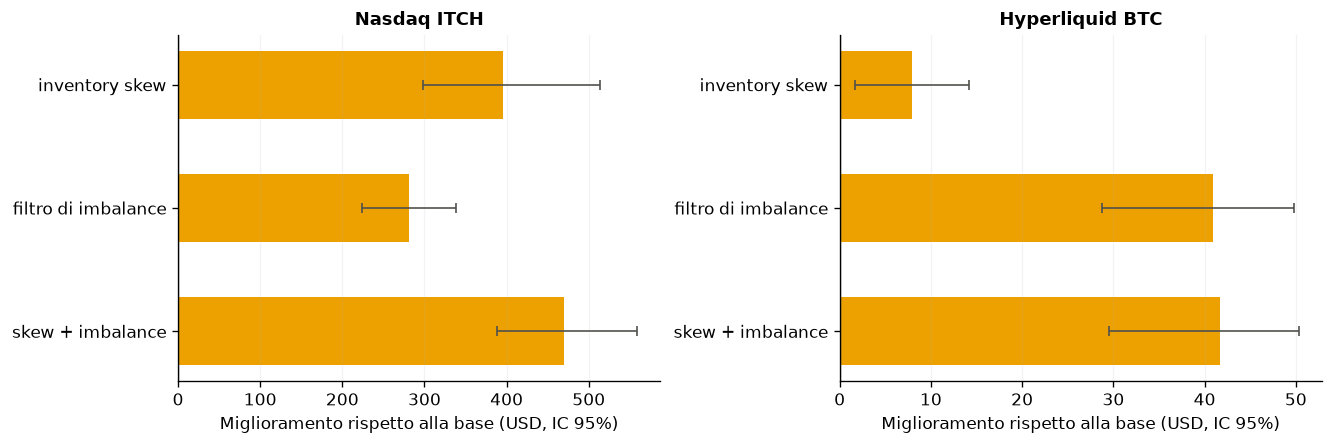

In [6]:
tables = []
for name, ref, fee in [("itch", "queue", "fees_nasdaq_base"), ("hyperliquid", "queue", "fees_tier0"),
                       ("fi2010", "price-through", None)]:
    eff = R.variant_effect(test, variants, name, NET[name], model=ref, fee_column=fee)
    eff.assign(dataset=R.DATASET_LABELS[name]).to_csv(ROOT / "results" / "tabella_varianti.csv",
                                                      mode="a" if tables else "w", header=not tables)
    table = R.variants_table(eff, 4 if name == "fi2010" else 1)
    table.index = pd.MultiIndex.from_product([[R.DATASET_LABELS[name]], table.index])
    tables.append(table)
display(pd.concat(tables))

vstress = R.load(ROOT, "variants_stress").query("dataset == 'itch'")
latency = vstress.groupby("param_latency_ns").net_nasdaq_base.mean()
display(Markdown(
    f"**Attenzione alla latenza.** La variante migliore su ITCH ({R.VARIANT_LABELS[vstress.variant.iloc[0]]}) funziona "
    f"solo se le cancellazioni sono istantanee: passa da {it(latency.iloc[0])} USD per sessione senza latenza a "
    f"{it(latency.iloc[1])} con 1 ms e {it(latency.iloc[-1])} con 100 ms. I market maker reali operano in microsecondi."))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
for ax, name in zip(axes, ["itch", "hyperliquid"]):
    eff = R.variant_effect(test, variants, name, NET[name], fee_column="fees_nasdaq_base" if name == "itch" else "fees_tier0").drop(index="base")
    y = np.arange(len(eff))[::-1]
    ax.barh(y, eff["differenza vs base"], color=R.COLORS["queue"], height=0.55)
    ax.errorbar(eff["differenza vs base"], y, xerr=[eff["differenza vs base"] - eff["diff IC95 basso"],
                eff["diff IC95 alto"] - eff["differenza vs base"]], fmt="none", ecolor=R.INK, capsize=3, linewidth=1)
    ax.set_yticks(y, eff.index)
    ax.axvline(0, color=R.INK, linewidth=0.8)
    ax.set(title=R.DATASET_LABELS[name], xlabel="Miglioramento rispetto alla base (USD, IC 95%)")
    ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "varianti_strategia.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Costi e latenza della strategia base (E5)

Commissioni e prezzo di liquidazione non cambiano le decisioni della strategia, quindi si possono ricalcolare dalle stesse esecuzioni: la colonna *liquidazione al midpoint* è il limite teorico in cui chiudere l'inventario non costa nulla. La latenza invece cambia le esecuzioni e va simulata.

,liquidazione al midpoint,lordo,con rebate Nasdaq,senza rebate,commissioni base,commissioni ridotte
dataset,,,,,,
Nasdaq ITCH,"-301,7","-570,3","-540,6","-674,3",—,—
Hyperliquid BTC,"-2,0","-3,2",—,—,"-47,3","-16,1"


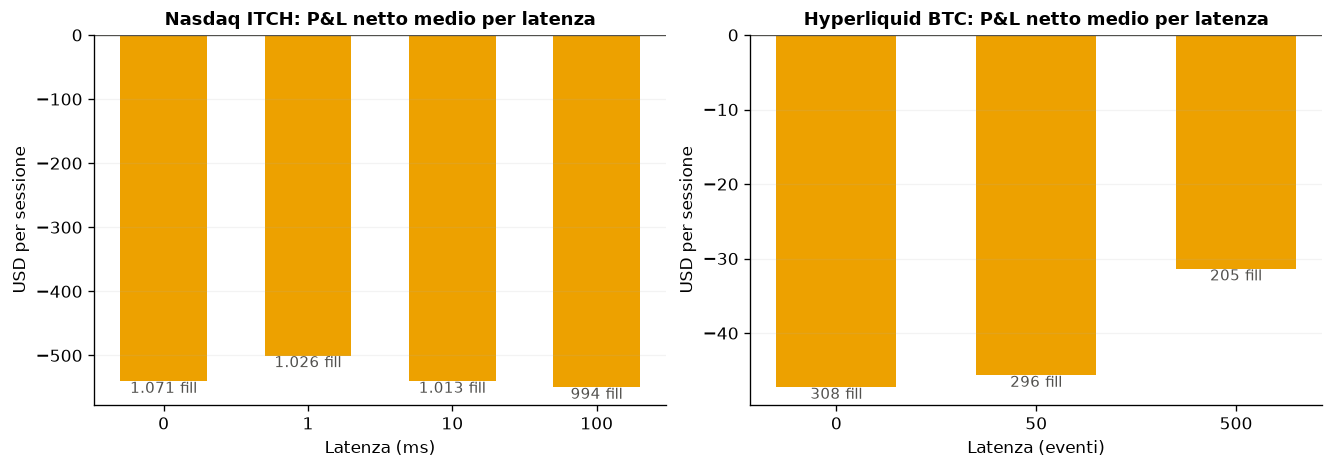

In [7]:
queue = test[test.model == "queue"]
scen = []
for name, fees, labels in [("itch", ["lordo", "nasdaq_base", "senza_rebate"], ["lordo", "con rebate Nasdaq", "senza rebate"]),
                           ("hyperliquid", ["lordo", "tier0", "tier_alto"], ["lordo", "commissioni base", "commissioni ridotte"])]:
    g = queue[queue.dataset == name]
    row = {"dataset": R.DATASET_LABELS[name], "liquidazione al midpoint": it(g.pnl_midpoint_liquidation.mean(), 1)}
    row.update({label: it(g[f"net_{f}"].mean(), 1) for f, label in zip(fees, labels)})
    scen.append(row)
display(pd.DataFrame(scen).set_index("dataset").fillna("—"))

stress = R.load(ROOT, "stress")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for ax, name, col, unit, fee, scale in [(axes[0], "itch", "param_latency_ns", "ms", "net_nasdaq_base", 1e6),
                                         (axes[1], "hyperliquid", "param_latency_events", "eventi", "net_tier0", 1)]:
    agg = stress[stress.dataset == name].groupby(col).agg(netto=(fee, "mean"), fill=("maker_fills", "mean"))
    labels = [it(v / scale, 0 if v == 0 or v / scale >= 1 else 1) for v in agg.index]
    ax.bar(labels, agg.netto, color=R.COLORS["queue"], width=0.6)
    for k, (v, f) in enumerate(zip(agg.netto, agg.fill)):
        ax.text(k, v, f"{it(f)} fill", ha="center", va="top" if v < 0 else "bottom", color=R.INK, fontsize=9)
    ax.axhline(0, color=R.INK, linewidth=0.8)
    ax.set(title=f"{R.DATASET_LABELS[name]}: P&L netto medio per latenza", xlabel=f"Latenza ({unit})", ylabel="USD per sessione")
    ax.grid(axis="x", visible=False)
fig.savefig(FIGURES / "stress_latenza.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Altre metriche del piano (§5.1)

Valori medi per sessione di test con la coda FIFO (ITCH, Hyperliquid) o `price-through` (FI-2010).

In [8]:
metric_rows = []
for name, ref in [("fi2010", "price-through"), ("itch", "queue"), ("hyperliquid", "queue")]:
    g = test[(test.dataset == name) & (test.model == ref)]
    d = 6 if name == "fi2010" else 2
    metric_rows.append({"dataset": R.DATASET_LABELS[name],
                        "coppie quotate": it(g.pairs_placed.mean()),
                        "coppie con entrambi i lati eseguiti": pct(g.fill_rate_pairs.mean(), 0),
                        "P&L per coppia": it(g.pnl_per_pair.mean(), d),
                        "drawdown massimo": it(g.max_drawdown.mean(), d),
                        "controvalore scambiato": it(g.turnover.mean()),
                        "inventario massimo raggiunto": it(g.max_abs_inventory_seen.max(), 2)})
display(pd.DataFrame(metric_rows).set_index("dataset"))

,coppie quotate,coppie con entrambi i lati eseguiti,P&L per coppia,drawdown massimo,controvalore scambiato,inventario massimo raggiunto
dataset,,,,,,
FI-2010,70,44%,"-0,000033","0,007901",30,"1,00"
Nasdaq ITCH,733,26%,"-0,77","588,55",15.837.570,"100,00"
Hyperliquid BTC,370,8%,"-0,01","3,34",162.407,"0,01"


## 8. Prestazioni del software

Tempo e memoria per singola simulazione (ognuna eseguita in un processo separato) e velocità del parser ITCH. La vista L2 dei dati order-level richiede comunque di ricostruire il book: il costo del maggiore dettaglio sta nella lettura e nella ricostruzione dei dati, non nella regola di esecuzione.

In [9]:
perf = test.groupby(["dataset", "model"]).agg(secondi=("seconds", "mean"), aggiornamenti=("records", "mean"),
                                              al_secondo=("records_per_second", "mean"), memoria_MB=("peak_memory_mb", "max"))
perf.index = perf.index.map(lambda k: (R.DATASET_LABELS[k[0]], R.LABELS[k[1]]))
display(perf.style.format({"secondi": "{:,.1f}", "aggiornamenti": "{:,.0f}", "al_secondo": "{:,.0f}", "memoria_MB": "{:,.0f}"}))
itch_ingest = pd.DataFrame(R.load_json(ROOT, "ingest/itch")["sessions"])
display(Markdown(f"Parser ITCH: {it(itch_ingest.messages.sum() / 1e9, 2)} miliardi di messaggi in 7 giornate, "
                 f"{it(itch_ingest.messages_per_second.mean() / 1e6, 1)} milioni al secondo per processo."))

Parser ITCH: 2,35 miliardi di messaggi in 7 giornate, 1,3 milioni al secondo per processo.

## 9. Risposta alla domanda di ricerca

In [10]:
criteria = []
for name in ["itch", "hyperliquid"]:
    g = queue[queue.dataset == name]
    limit = {"itch": 100, "hyperliquid": 0.01}[name]
    criteria.append({"dataset": R.DATASET_LABELS[name],
                     "P&L netto positivo nel test": "sì" if g[NET[name]].mean() > 0 else "no",
                     "sessioni positive": pct((g[NET[name]] > 0).mean(), 0),
                     "inventario sotto controllo": "sì" if (g.max_abs_inventory_seen <= limit + 1e-9).all() else "no"})
display(pd.DataFrame(criteria).set_index("dataset"))
display(Markdown(f"""
**Risposta: no.** Con la simulazione della coda reale la strategia non soddisfa il criterio del piano in nessuno dei due
mercati. Su Nasdaq ITCH perde in media {it(-it_q['mean'])} USD netti per sessione (IC 95% {it(it_q['low'])}; {it(it_q['high'])}),
mentre la stessa strategia valutata con `touch` sugli stessi dati sembrerebbe guadagnare {it(it_t['mean'])} USD per sessione.
Su Hyperliquid perde {it(-hl_q['mean'], 1)} USD per ora.

**Cosa significa.** Un backtest con regole di esecuzione L2, in particolare `touch`, può trasformare in guadagno una
strategia che con esecuzioni realistiche perde. La causa della perdita è la selezione avversa (e, su Hyperliquid, le
commissioni); il filtro di volatilità e le varianti la riducono ma non la eliminano, e il vantaggio delle varianti
sparisce con pochi millisecondi di latenza.

**Limiti.** Cinque giornate di test ITCH (le uniche pubblicate gratuitamente dal Nasdaq) e quattro ore Hyperliquid; gli
ordini simulati non influenzano il mercato; latenza costante; commissioni indicative. La tesi misura la distorsione
del backtest, non la redditività di strategie professionali, che usano velocità, rebate migliori e coperture.
"""))

,P&L netto positivo nel test,sessioni positive,inventario sotto controllo
dataset,,,
Nasdaq ITCH,no,0%,sì
Hyperliquid BTC,no,0%,sì



**Risposta: no.** Con la simulazione della coda reale la strategia non soddisfa il criterio del piano in nessuno dei due
mercati. Su Nasdaq ITCH perde in media 541 USD netti per sessione (IC 95% -660; -435),
mentre la stessa strategia valutata con `touch` sugli stessi dati sembrerebbe guadagnare 139.086 USD per sessione.
Su Hyperliquid perde 47,3 USD per ora.

**Cosa significa.** Un backtest con regole di esecuzione L2, in particolare `touch`, può trasformare in guadagno una
strategia che con esecuzioni realistiche perde. La causa della perdita è la selezione avversa (e, su Hyperliquid, le
commissioni); il filtro di volatilità e le varianti la riducono ma non la eliminano, e il vantaggio delle varianti
sparisce con pochi millisecondi di latenza.

**Limiti.** Cinque giornate di test ITCH (le uniche pubblicate gratuitamente dal Nasdaq) e quattro ore Hyperliquid; gli
ordini simulati non influenzano il mercato; latenza costante; commissioni indicative. La tesi misura la distorsione
del backtest, non la redditività di strategie professionali, che usano velocità, rebate migliori e coperture.


## Glossario

| Termine | Significato |
|---|---|
| **Limit order book (LOB)** | Elenco degli ordini di acquisto e vendita in attesa su uno strumento, ordinati per prezzo. |
| **L1, L2, L3, L4** | Livelli di dettaglio dei dati: L1 solo i prezzi migliori; L2 prezzi e volumi aggregati per livello; L3 ogni singolo ordine (*market by order*); L4 ogni ordine con l'identità di chi lo ha inserito. |
| **Best bid / best ask** | Miglior prezzo a cui qualcuno è disposto a comprare / a vendere. |
| **Spread** | Differenza tra best ask e best bid: il guadagno massimo di un market maker su una coppia di ordini. |
| **Tick** | Passo minimo di prezzo (1 centesimo per le azioni Nasdaq, 1 USD per BTC su Hyperliquid). |
| **Midpoint** | Media tra best bid e best ask; usato come prezzo di riferimento. |
| **Market maker** | Operatore che inserisce ordini su entrambi i lati del book e guadagna sullo spread, fornendo liquidità. |
| **Quota** | Ordine passivo inserito dal market maker (qui: uno in acquisto e uno in vendita, una *coppia*). |
| **Ordine limite / a mercato** | Il primo resta nel book a un prezzo fissato; il secondo viene eseguito subito al prezzo migliore disponibile. |
| **Maker / taker** | Chi fornisce liquidità con un ordine che resta nel book / chi la prende con un ordine che viene eseguito subito. |
| **Fill (esecuzione)** | Esecuzione, totale o *parziale*, di un ordine. |
| **Priorità prezzo-tempo, coda FIFO** | A parità di prezzo viene eseguito prima l'ordine inserito prima (*first in, first out*). |
| **Posizione in coda** | Quanto volume c'è davanti al proprio ordine allo stesso prezzo. |
| **Regola di fill L2** | Regola che deduce se un ordine è stato eseguito guardando solo i prezzi aggregati: `touch`, `price-through`, `cross`. |
| **touch** | Un acquisto è eseguito quando il best bid è uguale o inferiore alla quota (regola ottimista). |
| **price-through** | Un acquisto è eseguito quando il best bid scende sotto la quota. |
| **cross** | Un acquisto è eseguito quando il best ask scende fino alla quota. |
| **Coda FIFO (queue aware)** | Simulazione che mette la quota in fondo alla coda reale e la esegue solo quando le esecuzioni arrivano fino a lei; richiede dati L3 o L4. |
| **Inventario** | Quantità dello strumento posseduta (positiva) o venduta allo scoperto (negativa) in un dato momento. |
| **Liquidazione** | Chiusura dell'inventario con un ordine a mercato. |
| **Costo di liquidazione** | Quanto si perde chiudendo a mercato invece che al midpoint (circa mezzo spread per unità). |
| **Selezione avversa** | Tendenza a essere eseguiti proprio quando il prezzo sta per muoversi contro: chi scambia con il market maker spesso sa qualcosa in più. |
| **Markout** | Variazione del midpoint in un intervallo dopo un'esecuzione; misura la selezione avversa. |
| **Edge maker (spread incassato)** | Guadagno di un'esecuzione rispetto al midpoint del momento. |
| **P&L lordo / netto** | Profitto o perdita prima / dopo commissioni e rebate. |
| **Commissione, rebate** | Costo pagato all'exchange per ogni scambio; il rebate è un compenso pagato a chi fornisce liquidità. |
| **Post-only** | Ordine che viene rifiutato se verrebbe eseguito subito: garantisce di restare maker. |
| **Latenza** | Ritardo tra la decisione e il momento in cui l'ordine (o la cancellazione) arriva sul mercato. |
| **Volatilità** | Ampiezza dei movimenti del prezzo; qui la deviazione standard dei rendimenti del midpoint. |
| **Finestra mobile** | Ultimo tratto di dati (in osservazioni, eventi o secondi) su cui si calcola la volatilità. |
| **Percentile, quantile** | Valore sotto cui cade una certa quota dei dati: il 50° percentile (mediana) lascia sotto metà dei valori. |
| **Regime di bassa volatilità** | Periodi in cui la volatilità è sotto la soglia: gli unici in cui la strategia opera. |
| **Calibrazione, validazione, test** | Divisione cronologica dei dati: stimare le soglie, scegliere i parametri, misurare il risultato senza più modificarli. |
| **Ablazione** | Ripetere l'esperimento togliendo un componente (qui il filtro di volatilità) per misurarne il contributo. |
| **Inventory skew** | Variante che smaltisce l'inventario con ordini passivi invece di liquidare a mercato. |
| **Imbalance** | Squilibrio dei volumi al miglior prezzo: (volume in acquisto − volume in vendita) / somma; anticipa la direzione del prezzo. |
| **Sessione** | Unità di analisi indipendente: un titolo in una giornata o un'ora di negoziazione. |
| **Intervallo di confidenza (IC 95%), bootstrap** | Intervallo che contiene il valore medio "vero" con il 95% di confidenza; stimato ricampionando le sessioni (*bootstrap*). |
| **Differenza appaiata** | Confronto fatto sessione per sessione tra due versioni della strategia sugli stessi dati. |
| **Drawdown** | Massima perdita dal punto più alto della curva di equity. |
| **Turnover** | Controvalore totale scambiato. |
| **Equity, mark to market** | Valore del conto (cassa più inventario valutato al midpoint corrente). |
| **ITCH** | Protocollo del Nasdaq che trasmette ogni evento del book, ordine per ordine. |
| **FI-2010** | Dataset accademico di book L2 a 10 livelli di cinque titoli finlandesi, con prezzi normalizzati. |
| **Book diff** | Modifica elementare del book (nuovo ordine, aggiornamento, rimozione) nei dati Hyperliquid. |
| **Parquet, SHA-256** | Formato di file a colonne per i dati intermedi; impronta digitale che verifica l'integrità dei file. |